In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero

from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.ModelRunner import ModelRunner
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2
from halcyon.TidyDfResults import TidyDfResults

from copy import deepcopy
from halcyon.Simulators.NoiseLevel import NoiseLevel

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.ModelRunner import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging
from networkx import number_weakly_connected_components
import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Simulating data

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [100]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [5]
sparsity_list = [0.1]
out_path = Path("../data/hybrid_model_with_noise") 

In [3]:
sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False,
                noise_level=NoiseLevel.ALLNOISE,
            )
            sim_outputs.append(sim_output) 
sim_outputs

2026-02-02 17:27:24,962 - INFO - Generating network
2026-02-02 17:27:31,889 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_17*Node_5*Node_2) + ~(Node_28*Node_19*Node_4) + ~(Node_29*Node_13~Node_24)
my_network: Node_1: ~(Node_15*Node_71~Node_20~Node_50) + ~(Node_8*Node_0) + (Node_31) + ~(Node_11)
my_network: Node_2: (Node_30) + (Node_12~Node_1) + (Node_37) + (Node_3*Node_23~Node_35) + ~(Node_7) + (Node_17) + ~(Node_6)
my_network: Node_3: (Node_30*Node_7~Node_6~Node_17) + ~(Node_23*Node_37*Node_2~Node_35) + ~(Node_12*Node_53*Node_43)
my_network: Node_4: (Node_28*Node_5~Node_24) + ~(Node_1*Node_19~Node_0~Node_9)
my_network: Node_5: ~(Node_19*Node_57*Node_29~Node_13) + (Node_4*Node_0) + ~(Node_24)
my_network: Node_6: (Node_3*Node_61*Node_37) + (No

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1'), network_name='my_network', nr_genes=100, nr_modules=5, sparsity=0.1, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fecac6a82b0>, noise_level=<NoiseLevel.ALLNOISE: '_'>, normalise_time_series=True)]

1


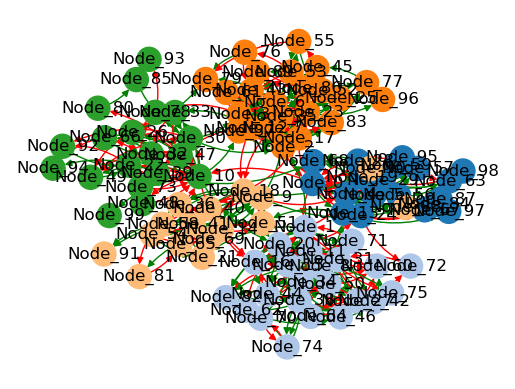

In [4]:
sim_output = sim_outputs[0]
# Do clustering
sim_output.network.do_clustering()

print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [5]:
for i, module in enumerate(sim_output.network._clustering):
    if 'Node_93' in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break
genes_to_select

Module: 4
Size: 19


['Node_26',
 'Node_80',
 'Node_33',
 'Node_22',
 'Node_47',
 'Node_93',
 'Node_32',
 'Node_10',
 'Node_85',
 'Node_99',
 'Node_73',
 'Node_66',
 'Node_48',
 'Node_78',
 'Node_39',
 'Node_30',
 'Node_92',
 'Node_49',
 'Node_94']

So select module 4 now for funsies

## Create dataset for training later on

In [6]:
# From sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = sim_output.create_datasets()

In [ ]:
single_ko_dataset.genes

In [ ]:
time_scaling_factor

# Trainers (with different models) creation

In [7]:
train_jobs : list[ModelRunner] = []

## Mech model

In [8]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=(), from_gnw=True, device='cuda:1')
# Select only genes from specific module
mm.select_genes(genes_to_select, goldstandard_signed_file_for_expression_substitution  = sim_output.data_path / f'{network_name}_goldstandard_signed.tsv')
# Fit MM on this data (skip for now?)
print(mm.modelled_gene_labels)
mm.set_timescaler(time_scaling_factor)


2026-02-02 17:28:27,199 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/my_network.xml


['Node_26', 'Node_80', 'Node_33', 'Node_22', 'Node_47', 'Node_93', 'Node_32', 'Node_10', 'Node_85', 'Node_99', 'Node_73', 'Node_66', 'Node_48', 'Node_78', 'Node_39', 'Node_30', 'Node_92', 'Node_49', 'Node_94']


In [9]:
# Creating MM trainer even though it cannot be trained
mm_trainer = ModelRunner(
    mm,
    save_dir = sim_output.data_path,
    nr_epochs=1,
    batch_size=32,
    # optimizer_fn=lambda x: None
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

## ML and Hybrid model

In [10]:

# for hidden_size in [2, 5, 10]:
#     for do_only_pos in [True, False]:

for hidden_size in [20, 50]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=single_ko_dataset.genes,
                    hidden_size=hidden_size,
                    condition_names=single_ko_dataset.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device='cuda:1'
            )

        # Create hybrid model with MM and with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device='cuda:1')

        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            model_runner = ModelRunner(
                model = model,
                save_dir = sim_output.data_path,
                batch_size=32,
                nr_epochs=20,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(model_runner)

## Baseline model (always derivative of 0)

In [11]:
baseline_model = AlwaysDerivativeZero(
    modelled_gene_labels=single_ko_dataset.genes,
    condition_names=single_ko_dataset.all_environments
    )

baseline_trainer = ModelRunner(
    baseline_model,
    save_dir = sim_output.data_path,
    batch_size=32,
    nr_epochs=0,
)
train_jobs.append(baseline_trainer)

2026-02-02 17:29:42,048 - INFO - Using GPU: Tesla T4 (compute capability 7.5)


In [12]:
for job in train_jobs:
    print(job)
    print()

Modelrunner (Model=PyTorchODE with hyperparams: [],
 optimizer=Adam,
 optimizer_kwargs={},
 nr_epochs=1,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:1', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=50', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:1', 'hidden_size=50', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=AlwaysDerivativeZero with hyperparams:

In [ ]:
train_jobs[0].train(dataset=single_ko_dataset)

/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))


In [ ]:
train_jobs[1].train(dataset=double_ko_dataset)

In [ ]:
train_jobs[0].predict(dataset=double_ko_dataset)

# Do training

In [ ]:
train_jobs[3].run_for_parallelisation_and_save()

In [ ]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(run_training_job, train_jobs)

# Plot results

In [ ]:
train_jobs

In [ ]:
# The above implementation works (but doesnt load from saved files)
tidy_df_creator = FittedTrainerList.load_saved_jobs(train_jobs)

## Single KOs

In [ ]:
dataset_getter = lambda trainer: trainer.dataset
conditions_to_map = tidy_df_creator.get_all_genes()[:3]

tidy_df = tidy_df_creator.predict_tidy_dataframe_for_all_models_specific_kos(
    conditions_to_map, dataset_getter
)

In [ ]:
tidy_df.df.head()

In [ ]:
tidy_df.to_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [ ]:
# example_genes = ['Node_99', 'Node_85', 'Node_48', 'Node_66', 'Node_12']

example_genes = ['Node_0', 'Node_1', 'Node_2']

In [ ]:
tidy_df.df = tidy_df.df[(tidy_df.df['gene'].isin(example_genes))]

In [ ]:
def quick_rename_of_cols(model_name):
    return model_name.replace('_synthesis_only_positive_True_lr_0.1', '').replace('_hidden_size_', '_h_')

In [ ]:
tidy_df.df.model = tidy_df.df.model.apply(quick_rename_of_cols)

In [ ]:
tidy_df.plot_model_plots()

In [ ]:
tidy_df.per_gene_mse_heatmap(robust=True,cmap='plasma')

In [ ]:
tidy_df = TidyDfResults.from_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [ ]:
fig_dir = out_path / 'figures'
fig_dir

In [ ]:
tidy_df.plot_r2()

In [ ]:
tidy_df.plot_mse_per_gene();plt.tight_layout();plt.savefig(fig_dir / 'mse_plot.eps')

In [ ]:
tidy_df.plot_scatterplot()

## Double KOs

In [ ]:
dataset_getter = lambda trainer: trainer.double_ko_dataset
conditions_to_map = tidy_df_creator.get_double_ko_combinations()
len(conditions_to_map)

Bit of debugging / development code

In [ ]:
tidy_df_creator.trainer_list = [tidy_df_creator.trainer_list[5]]

In [ ]:
conditions_to_map = [('Node_10', 'Node_47'), ('Node_0', 'Node_1'), ('Node_0', 'Node_10')][2:]
conditions_to_map

In [ ]:
tidy_df_double_ko = tidy_df_creator.predict_tidy_dataframe_for_all_models_specific_kos(
    conditions_to_map, dataset_getter
)


In [ ]:

tidy_df_double_ko.to_csv(out_path / "tidy_df_double_ko_predictions.csv")
# tidy_df.to_parquet(out_path / "tidy_df_single_ko_predictions.parquet")

In [ ]:
tidy_df_double_ko = TidyDfResults.from_csv(out_path / "tidy_df_double_ko_predictions.csv")

In [ ]:
tidy_df_double_ko.df.model = tidy_df_double_ko.df.model.apply(quick_rename_of_cols)

In [ ]:
tidy_df_double_ko.per_gene_mse_heatmap(robust=False,cmap='plasma')


In [ ]:
plt.savefig(fig_dir / 'double_ko_mse_heatmap.eps', bbox_inches='tight')

In [ ]:
tidy_df_double_ko.df.head()

In [ ]:
double_ko_genes_to_select = [
    "Node_33",
    "Node_26",
    "Node_32",
    "Node_10",
    "Node_30",
    "Node_22",
    "Node_80",
    "Node_99",
    "Node_92",
    "Node_93",
    "Node_17",
    "Node_0"
]
tidy_df_double_ko.df = tidy_df_double_ko.df[(tidy_df_double_ko.df['gene'].isin(double_ko_genes_to_select)) & (tidy_df_double_ko.df['condition'] == 'KO: Node_10, Node_47')]
tidy_df_double_ko.df.head()

In [ ]:
tidy_df_double_ko.plot_model_plots()

In [ ]:
g = tidy_df_double_ko.plot_mse_per_gene(split_by_condition_in_mm=True); 
g.figure.suptitle("Per-gene MSE for Double knockouts")
plt.tight_layout()
# plt.show()
plt.savefig(fig_dir / 'per_gene_mse_double_ko_split_by_ko_in_mm.svg')

In [ ]:
tidy_df_double_ko.plot_r2()
# plt.show()
plt.savefig(fig_dir / 'r2_plot_double_ko_split_by_ko_in_mm.eps')

In [ ]:
tidy_df_double_ko.kde_plot(subsample_first=True);plt.show()

In [ ]:
tidy_df_double_ko.plot_scatterplot();plt.show()

## Loss

In [ ]:
for result in tidy_df_creator.trainer_list:
    # print(result.loss_history)
    plt.plot(result.loss_history, label=result.get_save_file_name())
plt.legend()
plt.yscale('log')
# plt.xscale('log')
plt.tight_layout()
plt.show()
# plt.savefig(fig_dir / 'loss_history_plot.svg')